In [38]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Force CPU execution and clean console logs
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import classification_report, confusion_matrix

# Reproducibility
tf.random.set_seed(42)
np.random.seed(42)

print(f"TensorFlow Version: {tf.__version__}")
print("Configured for CPU execution.")

TensorFlow Version: 2.20.0
Configured for CPU execution.


In [39]:
import os

# Automatically locate 'modified-dataset' inside /kaggle/input
DATASET_BASE = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "modified-dataset" in dirs:
        DATASET_BASE = os.path.join(root, "modified-dataset")
        break

if DATASET_BASE is None:
    raise FileNotFoundError("Could not find 'modified-dataset'. Check the Input panel.")

TRAIN_DIR = os.path.join(DATASET_BASE, "train")
VAL_DIR = os.path.join(DATASET_BASE, "val")
TEST_DIR = os.path.join(DATASET_BASE, "test")

print(f"Detected DATASET_BASE: {DATASET_BASE}\n")
print("Train folders:", sorted(os.listdir(TRAIN_DIR)))
print("Val folders:  ", sorted(os.listdir(VAL_DIR)))
print("Test folders: ", sorted(os.listdir(TEST_DIR)))

Detected DATASET_BASE: /kaggle/input/datasets/akshat103/e-waste-image-dataset/modified-dataset

Train folders: ['Battery', 'Keyboard', 'Microwave', 'Mobile', 'Mouse', 'PCB', 'Player', 'Printer', 'Television', 'Washing Machine']
Val folders:   ['Battery', 'Keyboard', 'Microwave', 'Mobile', 'Mouse', 'PCB', 'Player', 'Printer', 'Television', 'Washing Machine']
Test folders:  ['Battery', 'Keyboard', 'Microwave', 'Mobile', 'Mouse', 'PCB', 'Player', 'Printer', 'Television', 'Washing Machine']


In [40]:
IMG_SIZE = (160, 160) # Better aspect ratio retention, still ultra-fast on CPU
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Explicitly store and fix the class names list
CLASS_NAMES = list(train_ds.class_names)
NUM_CLASSES = len(CLASS_NAMES)

print(f"Total Classes ({NUM_CLASSES}): {CLASS_NAMES}")

Found 2400 files belonging to 10 classes.
Found 300 files belonging to 10 classes.
Found 300 files belonging to 10 classes.
Total Classes (10): ['Battery', 'Keyboard', 'Microwave', 'Mobile', 'Mouse', 'PCB', 'Player', 'Printer', 'Television', 'Washing Machine']


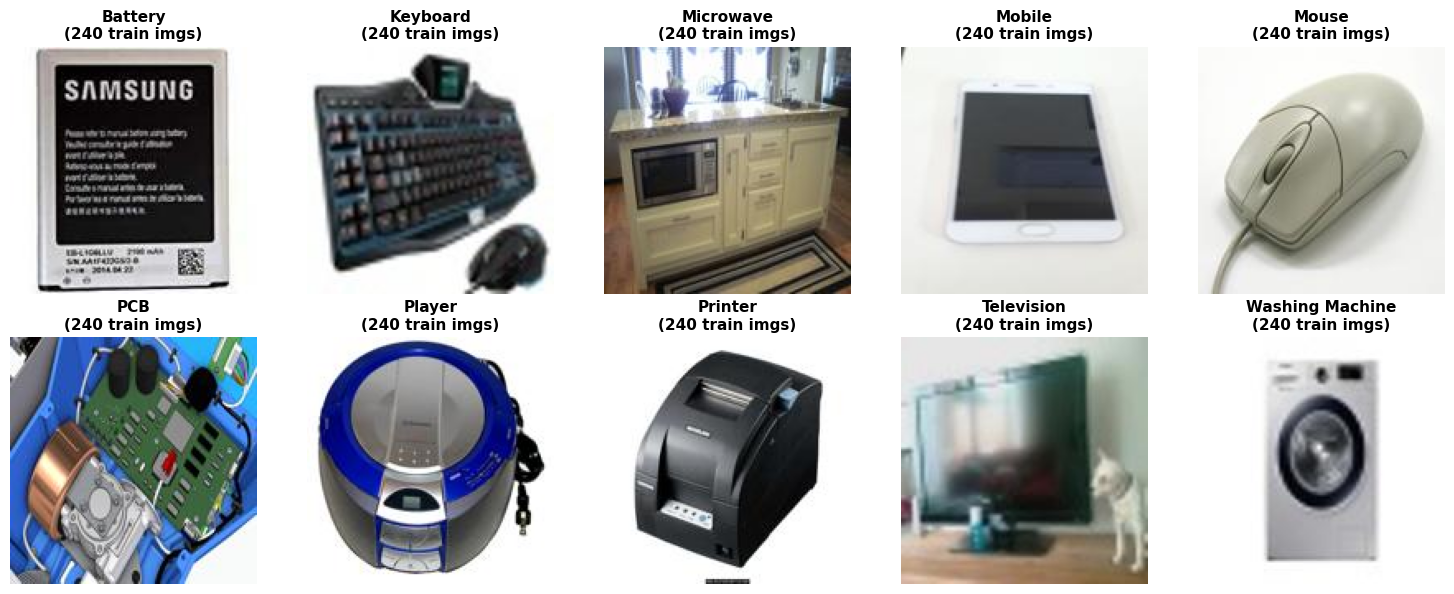

In [41]:
# ===== ADDED CELL: Display Sample Images per Category =====
import os
from PIL import Image
import matplotlib.pyplot as plt

cols = 5
rows = int(np.ceil(NUM_CLASSES / cols))

plt.figure(figsize=(15, 6))

for i, class_name in enumerate(CLASS_NAMES):
    class_folder = os.path.join(TRAIN_DIR, class_name)
    sample_files = [f for f in os.listdir(class_folder) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
    
    if sample_files:
        sample_img_path = os.path.join(class_folder, sample_files[0])
        img = Image.open(sample_img_path).convert('RGB')
        
        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.title(f"{class_name}\n({len(sample_files)} train imgs)", fontsize=11, fontweight='bold')
        plt.axis('off')

plt.tight_layout()
plt.savefig('/kaggle/working/sample_class_images.png', dpi=150)
plt.show()

In [42]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

AUTOTUNE = tf.data.AUTOTUNE

# Apply augmentation to training data only; cache and prefetch for CPU speed
train_ds = (
    train_ds
    .map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    .cache()
    .prefetch(buffer_size=AUTOTUNE)
)

val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

print("Data pipelines cached and ready for fast CPU throughput.")

Data pipelines cached and ready for fast CPU throughput.


In [43]:
from tensorflow.keras.applications import MobileNetV2

def build_edge_mobilenet(input_shape=(160, 160, 3), num_classes=10):
    inputs = layers.Input(shape=input_shape)
    
    # Built-in MobileNet preprocessing maps pixels to [-1, 1]
    x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
    
    # Pretrained lightweight backbone designed specifically for edge hardware
    base_model = MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights='imagenet'
    )
    # Freeze the base feature extractor so training is fast on CPU
    base_model.trainable = False
    
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(128, activation='relu')(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    return models.Model(inputs=inputs, outputs=outputs, name="Edge_MobileNetV2_Classifier")

model = build_edge_mobilenet(num_classes=NUM_CLASSES)
model.summary()

Model: "Edge_MobileNetV2_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_2 (TrueDivide)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_2 (Subtract)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [44]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_list = [
    callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)
]

# 8 epochs with pretrained features is plenty and takes ~3-4 minutes on CPU
EPOCHS = 8
start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_list
)

elapsed = time.time() - start_time
print(f"\nTraining completed in {elapsed / 60:.2f} minutes on CPU.")

Epoch 1/8
75/75 ━━━━━━━━━━━━━━━━━━━━ 43s 504ms/step - accuracy: 0.7671 - loss: 0.7259 - val_accuracy: 0.9233 - val_loss: 0.2406 - learning_rate: 0.0010
Epoch 2/8
75/75 ━━━━━━━━━━━━━━━━━━━━ 28s 376ms/step - accuracy: 0.9062 - loss: 0.2793 - val_accuracy: 0.9333 - val_loss: 0.2309 - learning_rate: 0.0010
Epoch 3/8
75/75 ━━━━━━━━━━━━━━━━━━━━ 28s 378ms/step - accuracy: 0.9421 - loss: 0.1778 - val_accuracy: 0.9367 - val_loss: 0.2292 - learning_rate: 0.0010
Epoch 4/8
75/75 ━━━━━━━━━━━━━━━━━━━━ 29s 383ms/step - accuracy: 0.9575 - loss: 0.1310 - val_accuracy: 0.9367 - val_loss: 0.2276 - learning_rate: 0.0010
Epoch 5/8
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 399ms/step - accuracy: 0.9667 - loss: 0.1024 - val_accuracy: 0.9367 - val_loss: 0.2288 - learning_rate: 0.0010
Epoch 6/8
75/75 ━━━━━━━━━━━━━━━━━━━━ 32s 426ms/step - accuracy: 0.9787 - loss: 0.0667 - val_accuracy: 0.9500 - val_loss: 0.2255 - learning_rate: 0.0010
Epoch 7/8
75/75 ━━━━━━━━━━━━━━━━━━━━ 33s 446ms/step - accuracy: 0.9883 - loss: 0.0472 - 

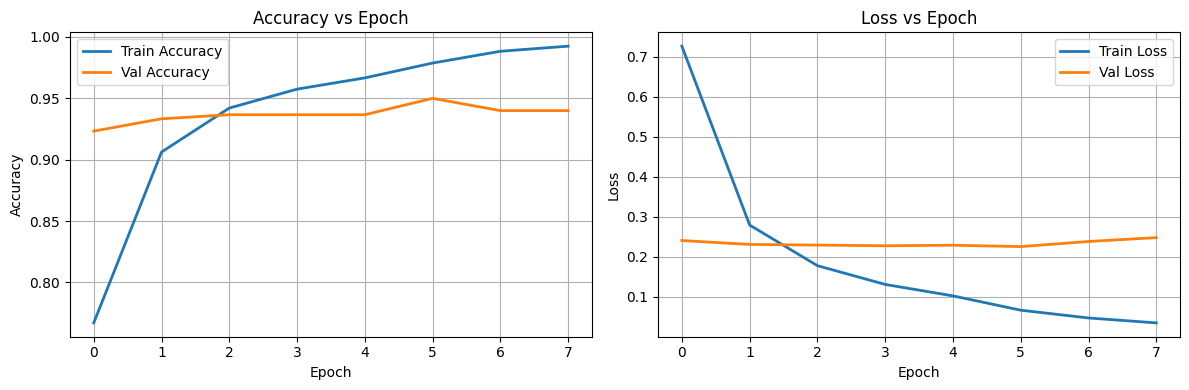

In [53]:
plt.figure(figsize=(12, 4))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Val Accuracy', linewidth=2)
plt.title('Accuracy vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Val Loss', linewidth=2)
plt.title('Loss vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('/kaggle/working/training_curves.png')
plt.show()

10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 324ms/step - accuracy: 0.9433 - loss: 0.1629

Final Test Accuracy on Unseen Data: 94.33%

=== CLASSIFICATION REPORT ===
                 precision    recall  f1-score   support

        Battery       1.00      0.83      0.91        30
       Keyboard       0.97      1.00      0.98        30
      Microwave       0.88      0.97      0.92        30
         Mobile       0.94      1.00      0.97        30
          Mouse       1.00      0.93      0.97        30
            PCB       0.97      0.93      0.95        30
         Player       0.85      0.97      0.91        30
        Printer       0.93      0.90      0.92        30
     Television       1.00      0.90      0.95        30
Washing Machine       0.94      1.00      0.97        30

       accuracy                           0.94       300
      macro avg       0.95      0.94      0.94       300
   weighted avg       0.95      0.94      0.94       300



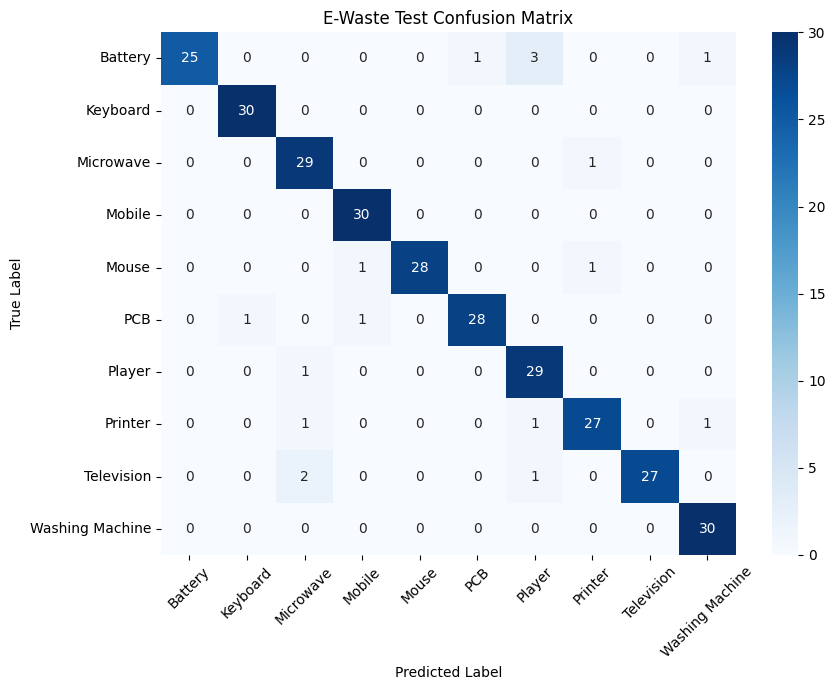

In [54]:
# Evaluate directly on the dedicated test dataset
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"\nFinal Test Accuracy on Unseen Data: {test_acc * 100:.2f}%\n")

# Collect predictions for full classification report
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('E-Waste Test Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('/kaggle/working/confusion_matrix.png')
plt.show()

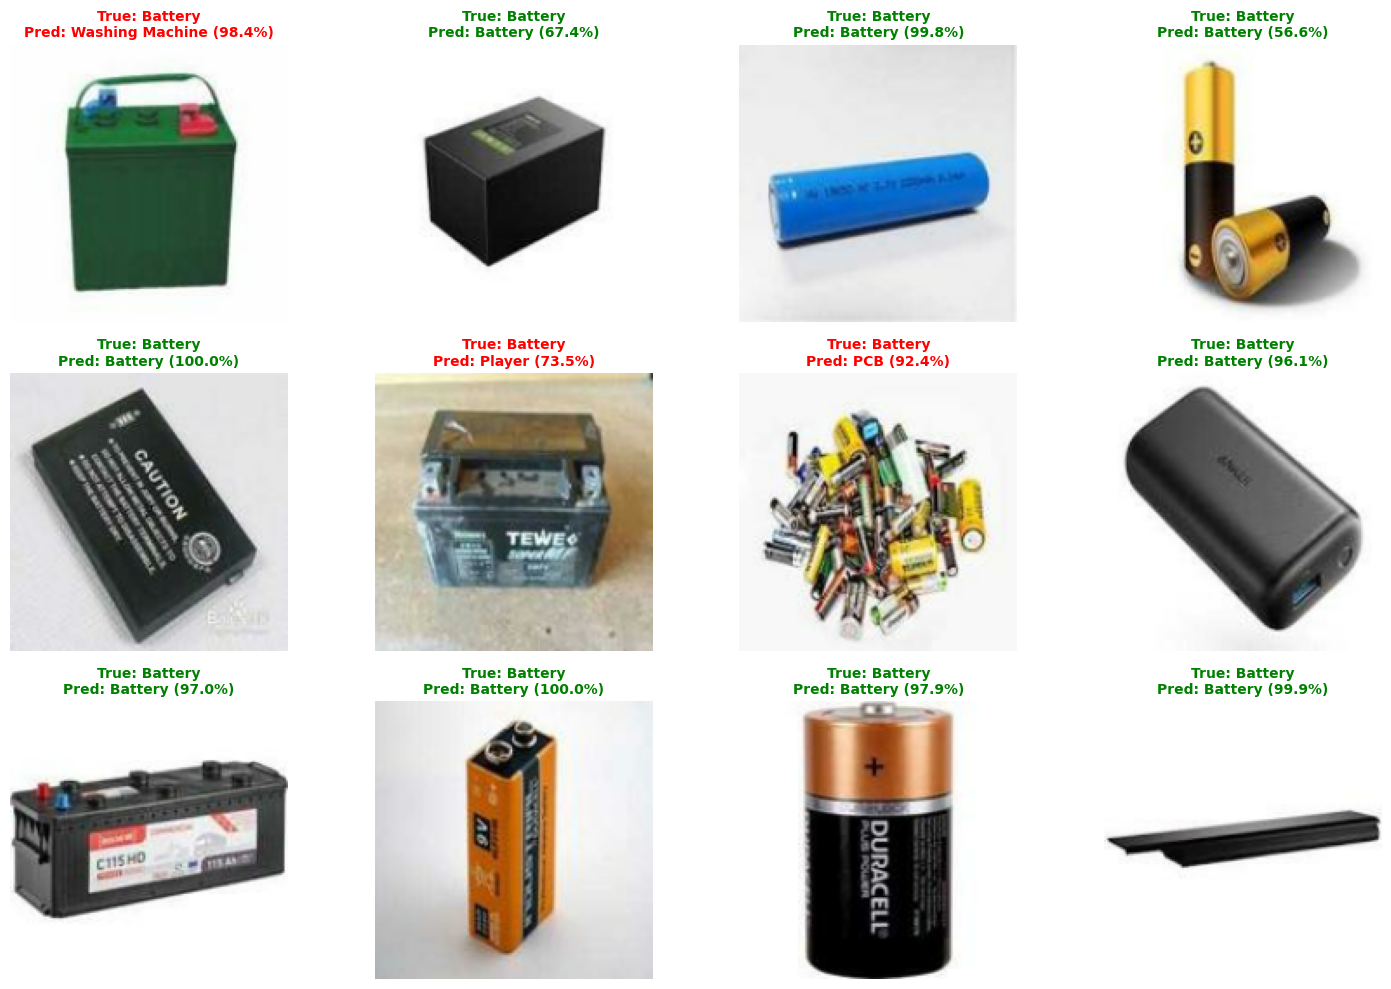

In [56]:
# ===== ADDED CELL: Visual Test Set Predictions Grid =====
# Take one batch of unseen test samples
for images, labels in test_ds.take(1):
    preds = model(images, training=False).numpy()
    pred_indices = np.argmax(preds, axis=1)
    true_indices = labels.numpy()

plt.figure(figsize=(15, 10))
num_to_show = min(12, len(images))

for i in range(num_to_show):
    ax = plt.subplot(3, 4, i + 1)
    img_display = images[i].numpy().astype("uint8")
    
    true_label = CLASS_NAMES[true_indices[i]]
    pred_label = CLASS_NAMES[pred_indices[i]]
    conf = preds[i][pred_indices[i]] * 100.0
    
    is_correct = (true_label == pred_label)
    title_color = "green" if is_correct else "red"
    
    plt.imshow(img_display)
    plt.title(f"True: {true_label}\nPred: {pred_label} ({conf:.1f}%)", color=title_color, fontsize=10, fontweight='bold')
    plt.axis("off")

plt.tight_layout()
plt.savefig('/kaggle/working/test_sample_predictions.png', dpi=150)
plt.show()

In [55]:
# Benchmark single-item latency simulating an edge conveyor sensor
# Updated input shape to match MobileNetV2 (160x160x3)
dummy_sample = tf.random.uniform(shape=(1, 160, 160, 3), dtype=tf.float32)

# Warm-up run
for _ in range(10):
    _ = model(dummy_sample)

# Latency measurement over 100 runs
latencies = []
for _ in range(100):
    t0 = time.perf_counter()
    _ = model(dummy_sample)
    latencies.append((time.perf_counter() - t0) * 1000.0)

mean_ms = np.mean(latencies)
p95_ms = np.percentile(latencies, 95)
fps = 1000.0 / mean_ms

print("=== EDGE SORTING INFERENCE BENCHMARK ===")
print(f"Average Latency: {mean_ms:.2f} ms per item")
print(f"95th Percentile: {p95_ms:.2f} ms")
print(f"Throughput:      {fps:.2f} items sorted per second")

=== EDGE SORTING INFERENCE BENCHMARK ===
Average Latency: 221.35 ms per item
95th Percentile: 231.52 ms
Throughput:      4.52 items sorted per second


In [57]:
# 1. Convert directly from the in-memory Keras model (Float32)
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

tflite_path = '/kaggle/working/model_float32.tflite'
with open(tflite_path, 'wb') as f:
    f.write(tflite_model)

# 2. Dynamic Range INT8 Quantization (Post-Training Quantization)
converter_quant = tf.lite.TFLiteConverter.from_keras_model(model)
converter_quant.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_quant = converter_quant.convert()

tflite_quant_path = '/kaggle/working/model_quantized_int8.tflite'
with open(tflite_quant_path, 'wb') as f:
    f.write(tflite_quant)

# Also save the native Keras model file for archiving
model.save('/kaggle/working/edge_ewaste_model.keras')

# Benchmark file footprints
f32_size = os.path.getsize(tflite_path) / 1024
int8_size = os.path.getsize(tflite_quant_path) / 1024

print("=== EDGE FOOTPRINT BENCHMARK ===")
print(f"Total Parameters:    {model.count_params():,}")
print(f"Float32 TFLite Size: {f32_size:.2f} KB")
print(f"INT8 Quantized Size: {int8_size:.2f} KB")
print(f"Memory Reduction:    {(f32_size / int8_size):.2f}x smaller")

INFO:tensorflow:Assets written to: /tmp/tmp9kty1ykg/assets


INFO:tensorflow:Assets written to: /tmp/tmp9kty1ykg/assets


Saved artifact at '/tmp/tmp9kty1ykg'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='input_layer_8')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  138822385310352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138821865417680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138821865413072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138822385307088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138822385305168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138821865419408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138821865408464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138821865413456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138821865413264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138821865419984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138821865408

W0000 00:00:1793038625.849158      50 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793038625.849229      50 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.


INFO:tensorflow:Assets written to: /tmp/tmp1wbwpxrk/assets


INFO:tensorflow:Assets written to: /tmp/tmp1wbwpxrk/assets


Saved artifact at '/tmp/tmp1wbwpxrk'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='input_layer_8')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  138822385310352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138821865417680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138821865413072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138822385307088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138822385305168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138821865419408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138821865408464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138821865413456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138821865413264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138821865419984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138821865408

W0000 00:00:1793038637.383272      50 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793038637.383322      50 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.


=== EDGE FOOTPRINT BENCHMARK ===
Total Parameters:    2,423,242
Float32 TFLite Size: 9306.95 KB
INT8 Quantized Size: 2615.91 KB
Memory Reduction:    3.56x smaller


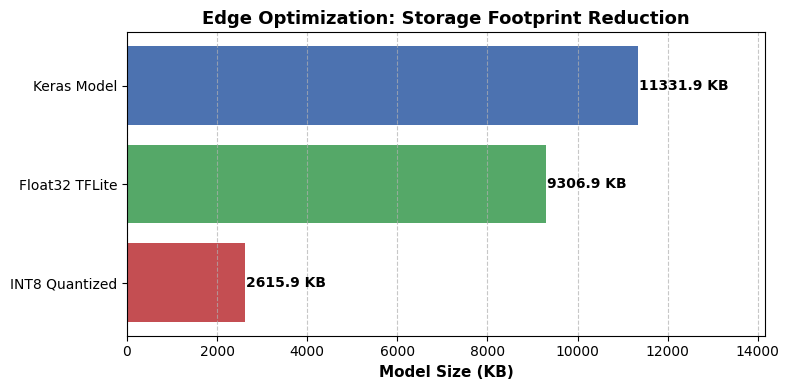

In [58]:
# ===== ADDED CELL: Edge Model Size Comparison Chart =====
keras_size = os.path.getsize('/kaggle/working/edge_ewaste_model.keras') / 1024

model_formats = ['Keras Model', 'Float32 TFLite', 'INT8 Quantized']
sizes_kb = [keras_size, f32_size, int8_size]

plt.figure(figsize=(8, 4))
bars = plt.barh(model_formats, sizes_kb, color=['#4C72B0', '#55A868', '#C44E52'])
plt.xlabel('Model Size (KB)', fontsize=11, fontweight='bold')
plt.title('Edge Optimization: Storage Footprint Reduction', fontsize=13, fontweight='bold')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 20, bar.get_y() + bar.get_height()/2, f"{width:.1f} KB", 
             va='center', ha='left', fontsize=10, fontweight='bold')

plt.xlim(0, max(sizes_kb) * 1.25)
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('/kaggle/working/edge_model_comparison.png', dpi=150)
plt.show()

In [59]:
import io
import ipywidgets as widgets
from IPython.display import display
from PIL import Image
import numpy as np
import tensorflow as tf

# Upload widget
upload_btn = widgets.FileUpload(
    accept='image/*',
    multiple=False,
    description='Upload Image'
)

output_area = widgets.Output()

def on_image_upload(change):
    with output_area:
        output_area.clear_output()
        if not upload_btn.value:
            return
        
        # Read the uploaded file bytes
        uploaded_file = upload_btn.value[0]
        content = uploaded_file['content']
        
        # Open and display image
        img = Image.open(io.BytesIO(content)).convert('RGB')
        
        # Preprocess to match training input (128x128)
        img_resized = img.resize((128, 128))
        img_array = np.array(img_resized, dtype=np.float32)
        img_batch = np.expand_dims(img_array, axis=0) # Shape: (1, 128, 128, 3)
        
        # Predict using your trained model
        preds = model.predict(img_batch, verbose=0)[0]
        pred_idx = np.argmax(preds)
        predicted_class = CLASS_NAMES[pred_idx]
        confidence = preds[pred_idx] * 100.0
        
        # Display side-by-side or stacked
        fig, ax = plt.subplots(figsize=(4, 4))
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"Prediction: {predicted_class}\nConfidence: {confidence:.2f}%", 
                     fontsize=12, fontweight='bold', color='green' if confidence > 60 else 'orange')
        plt.show()

upload_btn.observe(on_image_upload, names='value')

print("Click 'Upload Image' to test your lightweight model interactively:")
display(widgets.VBox([upload_btn, output_area]))

Click 'Upload Image' to test your lightweight model interactively:


In [60]:
import io
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import ipywidgets as widgets
from IPython.display import display
import tensorflow as tf

# 1. Fixed class names list matching the dataset
CLASS_NAMES = ['Battery', 'Keyboard', 'Microwave', 'Mobile', 'Mouse', 
               'PCB', 'Player', 'Printer', 'Television', 'Washing Machine']

# 2. Load the already-saved model from working storage
MODEL_PATH = '/kaggle/working/edge_ewaste_model.keras'

if os.path.exists(MODEL_PATH):
    model = tf.keras.models.load_model(MODEL_PATH)
    print("Saved model loaded successfully!")
else:
    raise FileNotFoundError(f"Model file not found at {MODEL_PATH}. Please run the training cell first.")

# 3. Interactive Upload Interface
upload_btn = widgets.FileUpload(accept='image/*', multiple=False, description='Upload Image')
output_area = widgets.Output()

def on_image_upload(change):
    with output_area:
        output_area.clear_output()
        if not upload_btn.value:
            return
        
        # Support both ipywidgets v7 (dict) and v8 (tuple of dicts or UploadedFile objects)
        raw_val = upload_btn.value
        if isinstance(raw_val, (tuple, list)):
            first_item = raw_val[0]
            content = first_item['content'] if isinstance(first_item, dict) else first_item.content
        elif isinstance(raw_val, dict):
            first_key = next(iter(raw_val))
            content = raw_val[first_key]['content']
        else:
            return
        
        # Load and pad image to retain aspect ratio
        img = Image.open(io.BytesIO(content)).convert('RGB')
        img_padded = ImageOps.pad(img, (160, 160), color=(255, 255, 255))
        img_array = np.array(img_padded, dtype=np.float32)
        img_batch = np.expand_dims(img_array, axis=0)
        
        # Direct call to prevent retracing warnings
        preds = model(tf.constant(img_batch), training=False).numpy()[0]
        top_indices = np.argsort(preds)[::-1][:3]
        
        best_idx = top_indices[0]
        best_class = CLASS_NAMES[best_idx]
        best_conf = float(preds[best_idx]) * 100.0
        
        # Display image and classification result
        fig, ax = plt.subplots(figsize=(5, 4))
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"Prediction: {best_class} ({best_conf:.2f}%)", 
                     fontsize=13, fontweight='bold', 
                     color='green' if best_conf > 50 else 'red')
        plt.show()
        
        print("Top 3 Predictions:")
        for idx in top_indices:
            print(f"  • {CLASS_NAMES[idx]}: {preds[idx]*100:.2f}%")

upload_btn.observe(on_image_upload, names='value')

print("Ready! Click 'Upload Image' to test:")
display(widgets.VBox([upload_btn, output_area]))

Saved model loaded successfully!
Ready! Click 'Upload Image' to test:
